In [2]:
# library
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from statsmodels.tools.eval_measures import rmse

In [3]:
# import 'tips' dataset
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [4]:
# show df
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [7]:
# describe between tip & total bill
tips[['total_bill','tip']].describe()

,total_bill,tip
count,244.000000,244.000000
mean,19.785943,2.998279
std,8.902412,1.383638
min,3.070000,1.000000
25%,13.347500,2.000000
50%,17.795000,2.900000
75%,24.127500,3.562500
max,50.810000,10.000000


In [9]:
# display correlation between tip and total_bill
tips[['total_bill','tip']].corr()

,total_bill,tip
total_bill,1.000000,0.675734
tip,0.675734,1.000000


<Axes: xlabel='total_bill', ylabel='tip'>

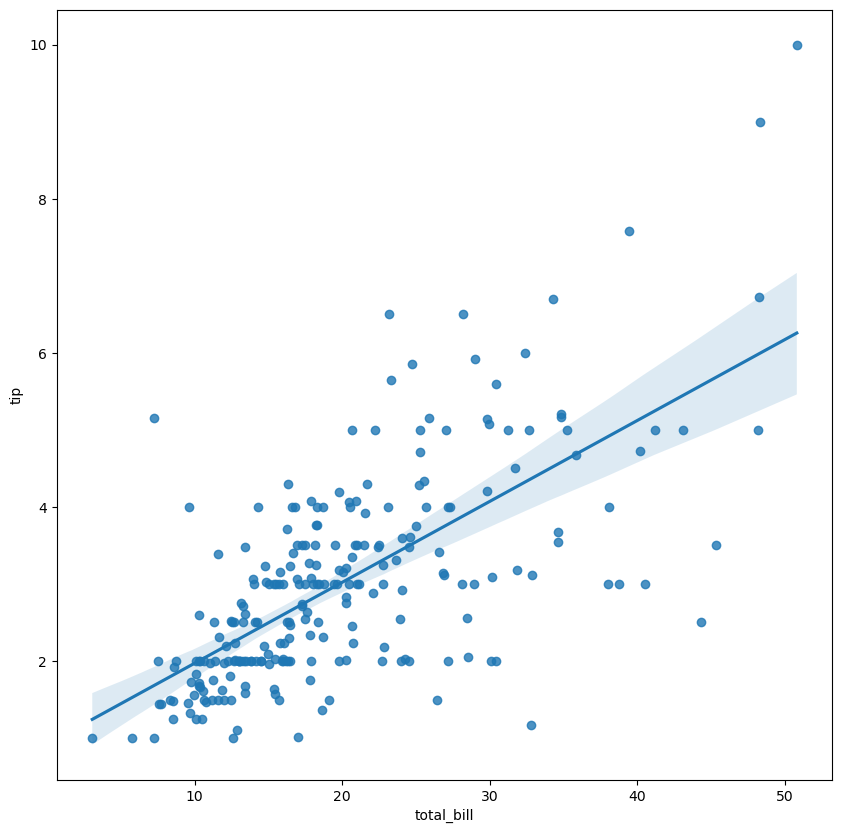

In [10]:
# plot regression line
plt.figure(figsize=(10,10))
sns.regplot(data=tips,x='total_bill',y='tip')

In [12]:
Y = tips['tip']
X = sm.add_constant(tips[['total_bill']])
display(Y,X)

0      1.01
1      1.66
2      3.50
3      3.31
4      3.61
       ... 
239    5.92
240    2.00
241    2.00
242    1.75
243    3.00
Name: tip, Length: 244, dtype: float64

,const,total_bill
0,1.0,16.99
1,1.0,10.34
2,1.0,21.01
3,1.0,23.68
4,1.0,24.59
...,...,...
239,1.0,29.03
240,1.0,27.18
241,1.0,22.67
242,1.0,17.82


In [13]:
# using Ordinary Least Squares to choose the best linear equation
sm_lm = sm.OLS(Y,X)
result = sm_lm.fit()

In [14]:
# print summary
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.457
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     203.4
Date:                Tue, 28 May 2024   Prob (F-statistic):           6.69e-34
Time:                        10:59:42   Log-Likelihood:                -350.54
No. Observations:                 244   AIC:                             705.1
Df Residuals:                     242   BIC:                             712.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9203      0.160      5.761      0.0

Y = 0.9203 + 0.1050x

F-Test: 
B1 is below than 0.05, indicate we have enough evidence to reject total bill have no affect for tip. Thus, we can conclude that total bill affect the tip.

T-Test (Partial test):
1. B0: P-value < 0.05, the model needs B0. (B0 is important to the line)
2. B1: P-value < 0.05, the model needs B1.

Paremeter Estimate:
B0 = 0.9203 : this is the condition where total_bills equal to zero. But, the domain for total_bill equal zero is not exist. This doesn't need to be interpreted because (from the domain), there is no people that paid free (x=0)
B1 = 0.1050 : when the total_bill increase by 1 dollar, the tip will be increased about 0.1050 dollar. Or, when total bill increase by 10 dollar, the tip will increase by 1.05 dollar. (this interpretation only when the total_bill falls between 3.07 dollar and between 50.01 dollar)

R-Square: 45.7%, the model can explain 45.7% variation of tips.

In [15]:
# create dataframe for prediction
y_predict = result.predict()
y_predict = pd.DataFrame(data=y_predict,columns=['prediction'])
y_predict

,prediction
0,2.704636
1,2.006223
2,3.126835
3,3.407250
4,3.502822
...,...
239,3.969131
240,3.774836
241,3.301175
242,2.791807


In [16]:
# create column 'y_predict' in tips
tips['y_pred'] = y_predict
tips

,total_bill,tip,sex,smoker,day,time,size,y_pred
0,16.99,1.01,Female,No,Sun,Dinner,2,2.704636
1,10.34,1.66,Male,No,Sun,Dinner,3,2.006223
2,21.01,3.50,Male,No,Sun,Dinner,3,3.126835
3,23.68,3.31,Male,No,Sun,Dinner,2,3.407250
4,24.59,3.61,Female,No,Sun,Dinner,4,3.502822
...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,3.969131
240,27.18,2.00,Female,Yes,Sat,Dinner,2,3.774836
241,22.67,2.00,Male,Yes,Sat,Dinner,2,3.301175
242,17.82,1.75,Male,No,Sat,Dinner,2,2.791807


In [17]:
# create column 'residual' in tips
tips['residual'] = tips['tip'] - tips['y_pred']
tips

,total_bill,tip,sex,smoker,day,time,size,y_pred,residual
0,16.99,1.01,Female,No,Sun,Dinner,2,2.704636,-1.694636
1,10.34,1.66,Male,No,Sun,Dinner,3,2.006223,-0.346223
2,21.01,3.50,Male,No,Sun,Dinner,3,3.126835,0.373165
3,23.68,3.31,Male,No,Sun,Dinner,2,3.407250,-0.097250
4,24.59,3.61,Female,No,Sun,Dinner,4,3.502822,0.107178
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,3.969131,1.950869
240,27.18,2.00,Female,Yes,Sat,Dinner,2,3.774836,-1.774836
241,22.67,2.00,Male,Yes,Sat,Dinner,2,3.301175,-1.301175
242,17.82,1.75,Male,No,Sat,Dinner,2,2.791807,-1.041807


In [20]:
# RMSE
np.sqrt(sum(pow(tips['residual'],2))/len(tips))

1.0178504025697377

In [22]:
# RMSE using library
rmse = rmse(tips['tip'],tips['y_pred'])
rmse

1.0178504025697377

<Axes: xlabel='total_bill', ylabel='tip'>

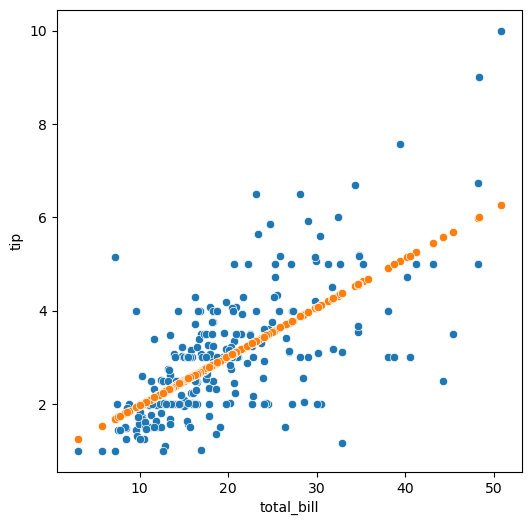

In [23]:
# plot the y_pred vs y_true (y_actual)
plt.figure(figsize=(6,6))
sns.scatterplot(x=tips['total_bill'],y=tips['tip'])
sns.scatterplot(x=tips['total_bill'],y=tips['y_pred'])